In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv(r"C:\Users\HomePC\Downloads\ds_salaries.csv")

In [4]:
df.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,SE,FT,Principal Data Scientist,80000,EUR,85847,ES,100,ES,L
1,2023,MI,CT,ML Engineer,30000,USD,30000,US,100,US,S
2,2023,MI,CT,ML Engineer,25500,USD,25500,US,100,US,S
3,2023,SE,FT,Data Scientist,175000,USD,175000,CA,100,CA,M
4,2023,SE,FT,Data Scientist,120000,USD,120000,CA,100,CA,M


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3755 entries, 0 to 3754
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           3755 non-null   int64 
 1   experience_level    3755 non-null   object
 2   employment_type     3755 non-null   object
 3   job_title           3755 non-null   object
 4   salary              3755 non-null   int64 
 5   salary_currency     3755 non-null   object
 6   salary_in_usd       3755 non-null   int64 
 7   employee_residence  3755 non-null   object
 8   remote_ratio        3755 non-null   int64 
 9   company_location    3755 non-null   object
 10  company_size        3755 non-null   object
dtypes: int64(4), object(7)
memory usage: 322.8+ KB


In [6]:
df.shape

(3755, 11)

In [35]:
df.isnull().sum()

In [7]:
df.drop_duplicates()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,SE,FT,Principal Data Scientist,80000,EUR,85847,ES,100,ES,L
1,2023,MI,CT,ML Engineer,30000,USD,30000,US,100,US,S
2,2023,MI,CT,ML Engineer,25500,USD,25500,US,100,US,S
3,2023,SE,FT,Data Scientist,175000,USD,175000,CA,100,CA,M
4,2023,SE,FT,Data Scientist,120000,USD,120000,CA,100,CA,M
...,...,...,...,...,...,...,...,...,...,...,...
3750,2020,SE,FT,Data Scientist,412000,USD,412000,US,100,US,L
3751,2021,MI,FT,Principal Data Scientist,151000,USD,151000,US,100,US,L
3752,2020,EN,FT,Data Scientist,105000,USD,105000,US,100,US,S
3753,2020,EN,CT,Business Data Analyst,100000,USD,100000,US,100,US,L


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3755 entries, 0 to 3754
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           3755 non-null   int64 
 1   experience_level    3755 non-null   object
 2   employment_type     3755 non-null   object
 3   job_title           3755 non-null   object
 4   salary              3755 non-null   int64 
 5   salary_currency     3755 non-null   object
 6   salary_in_usd       3755 non-null   int64 
 7   employee_residence  3755 non-null   object
 8   remote_ratio        3755 non-null   int64 
 9   company_location    3755 non-null   object
 10  company_size        3755 non-null   object
dtypes: int64(4), object(7)
memory usage: 322.8+ KB


In [ ]:
df.columns = df.columns.str.lower().str.strip()


In [41]:
#cat_col= ['experience_level', 'employment_type', 'job_title',
                #'salary_currency', 'employee_residence',
                #'company_location', 'company_size']

#for col in text_columns:
    #df[col] = df[col].astype(str).str.title()

In [9]:
df.dtypes

work_year              int64
experience_level      object
employment_type       object
job_title             object
salary                 int64
salary_currency       object
salary_in_usd          int64
employee_residence    object
remote_ratio           int64
company_location      object
company_size          object
dtype: object

In [45]:

Q1 = df['salary_in_usd'].quantile(0.25)
Q3 = df['salary_in_usd'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


In [46]:
# Remove outliers

df = df[(df['salary_in_usd'] >= lower_bound) & (df['salary_in_usd'] <= upper_bound)]

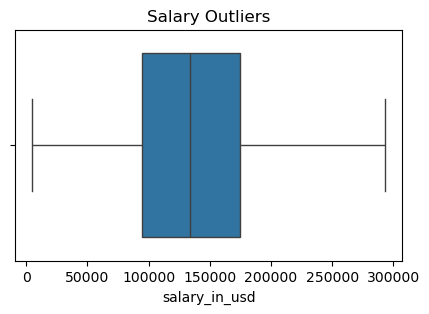

In [47]:
plt.figure(figsize=(5,3))
sns.boxplot(x=df["salary_in_usd"])
plt.title("Salary Outliers")
plt.show()

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3692 entries, 0 to 3754
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           3692 non-null   int64 
 1   experience_level    3692 non-null   object
 2   employment_type     3692 non-null   object
 3   job_title           3692 non-null   object
 4   salary              3692 non-null   int64 
 5   salary_currency     3692 non-null   object
 6   salary_in_usd       3692 non-null   int64 
 7   employee_residence  3692 non-null   object
 8   remote_ratio        3692 non-null   int64 
 9   company_location    3692 non-null   object
 10  company_size        3692 non-null   object
dtypes: int64(4), object(7)
memory usage: 346.1+ KB


In [9]:
df.describe()

,work_year,salary,salary_in_usd,remote_ratio
count,3692.000000,3.692000e+03,3692.000000,3692.000000
mean,2022.371885,1.880251e+05,134262.993770,46.289274
std,0.689827,6.767830e+05,57992.294349,48.589320
min,2020.000000,6.000000e+03,5132.000000,0.000000
25%,2022.000000,9.967500e+04,94916.250000,0.000000
50%,2022.000000,1.360000e+05,133916.000000,0.000000
75%,2023.000000,1.794000e+05,174500.000000,100.000000
max,2023.000000,3.040000e+07,293000.000000,100.000000


In [15]:
df['job_title'].value_counts().head(8)

job_title
Data Engineer                1040
Data Scientist                840
Data Analyst                  612
Machine Learning Engineer     289
Analytics Engineer            103
Data Architect                101
Research Scientist             82
Data Science Manager           58
Name: count, dtype: int64

In [13]:
df['job_title']

<bound method Series.sum of 0       Principal Data Scientist
1                    ML Engineer
2                    ML Engineer
3                 Data Scientist
4                 Data Scientist
                  ...           
3750              Data Scientist
3751    Principal Data Scientist
3752              Data Scientist
3753       Business Data Analyst
3754        Data Science Manager
Name: job_title, Length: 3755, dtype: object>

In [21]:
df['work_year'].value_counts()

work_year
2023    1747
2022    1644
2021     228
2020      73
Name: count, dtype: int64

In [33]:
top_salary = df.groupby("job_title")["salary_in_usd"].mean().sort_values(ascending=False).head(10)
top_salary

job_title
Cloud Data Architect                   250000.000000
Data Lead                              212500.000000
Principal Data Engineer                192500.000000
Principal Machine Learning Engineer    190000.000000
Applied Scientist                      183028.000000
Data Science Manager                   176458.215686
Data Infrastructure Engineer           175051.666667
Business Intelligence Engineer         174150.000000
Machine Learning Software Engineer     172133.333333
Head of Data                           167675.000000
Name: salary_in_usd, dtype: float64

In [26]:
df['job_title'].unique()

array(['Principal Data Scientist', 'ML Engineer', 'Data Scientist',
       'Applied Scientist', 'Data Analyst', 'Data Modeler',
       'Research Engineer', 'Analytics Engineer',
       'Business Intelligence Engineer', 'Machine Learning Engineer',
       'Data Strategist', 'Data Engineer', 'Computer Vision Engineer',
       'Data Quality Analyst', 'Compliance Data Analyst',
       'Data Architect', 'Applied Machine Learning Engineer',
       'Research Scientist', 'Data Analytics Manager',
       'Business Data Analyst', 'Applied Data Scientist',
       'Staff Data Analyst', 'ETL Engineer', 'Data DevOps Engineer',
       'AI Developer', 'Head of Data', 'Data Science Manager',
       'Data Manager', 'Machine Learning Researcher', 'Big Data Engineer',
       'Data Specialist', 'Lead Data Analyst', 'BI Data Engineer',
       'Director of Data Science', 'Machine Learning Scientist',
       'MLOps Engineer', 'Autonomous Vehicle Technician',
       'Applied Machine Learning Scientist', 'Lead 

In [25]:
#Who has the highest job salary

high_jobs = df.groupby('job_title')['salary_in_usd'].mean().sort_values(ascending=False)
(high_jobs).head(5)

#without .head() shows you the tops and down

job_title
Cloud Data Architect                   250000.0
Data Lead                              212500.0
Principal Data Engineer                192500.0
Principal Machine Learning Engineer    190000.0
Applied Scientist                      183028.0
Name: salary_in_usd, dtype: float64

In [48]:
df.describe()

,work_year,salary,salary_in_usd,remote_ratio
count,3692.000000,3.692000e+03,3692.000000,3692.000000
mean,2022.371885,1.880251e+05,134262.993770,46.289274
std,0.689827,6.767830e+05,57992.294349,48.589320
min,2020.000000,6.000000e+03,5132.000000,0.000000
25%,2022.000000,9.967500e+04,94916.250000,0.000000
50%,2022.000000,1.360000e+05,133916.000000,0.000000
75%,2023.000000,1.794000e+05,174500.000000,100.000000
max,2023.000000,3.040000e+07,293000.000000,100.000000


In [49]:
#Who has the highest job salary

high_jobs = df.groupby('job_title')['salary_in_usd'].mean().sort_values(ascending=False)
(high_jobs).head(60)

#without .head() shows you the tops and down

job_title
Cloud Data Architect                        250000.000000
Data Lead                                   212500.000000
Principal Data Engineer                     192500.000000
Principal Machine Learning Engineer         190000.000000
Applied Scientist                           183028.000000
Data Science Manager                        176458.215686
Data Infrastructure Engineer                175051.666667
Business Intelligence Engineer              174150.000000
Machine Learning Software Engineer          172133.333333
Head of Data                                167675.000000
Principal Data Scientist                    167052.714286
Machine Learning Scientist                  163220.076923
Director of Data Science                    163149.777778
Research Engineer                           163108.378378
ML Engineer                                 158352.441176
Data Architect                              157691.020202
Data Science Lead                           156334.375000
Mach

In [16]:
df['experience_level'].unique()

array(['SE', 'MI', 'EN', 'EX'], dtype=object)

In [30]:
df['employment_type'].unique()

array(['FT', 'CT', 'FL', 'PT'], dtype=object)

In [36]:
df['employment_type'].value_counts()

employment_type
FT    3718
PT      17
CT      10
FL      10
Name: count, dtype: int64

In [40]:
df['experience_level'].value_counts()

experience_level
SE    2473
MI     800
EN     319
EX     100
Name: count, dtype: int64

In [50]:
#avg salary
avg_salary_exp = df.groupby('experience_level')['salary_in_usd'].mean()
(avg_salary_exp)

experience_level
EN     77852.072100
EX    177028.260000
MI    102749.267500
SE    150004.820865
Name: salary_in_usd, dtype: float64

1.People who  are on the experience level earn much more higher than people in every other level
 2.followed by people in the senior level who earns at least 50% more than the people at the middle level
 3.followed by the middele level who maybe are still in probation before advancing to the senior level
 4.and finally we have the entry level, people who just got their degree and we recruited most recently

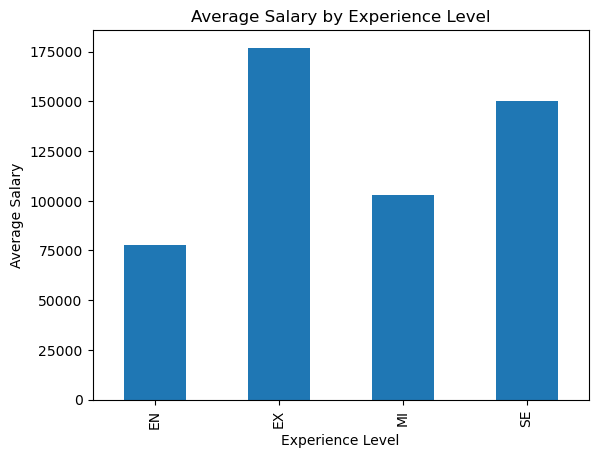

In [31]:
avg_salary_exp.plot(kind='bar')
plt.xlabel('Experience Level')
plt.ylabel('Average Salary')
plt.title('Average Salary by Experience Level')
plt.show()

In [18]:
#df['job_title'].unique()

In [28]:
df['company_size'].unique()

array(['L', 'S', 'M'], dtype=object)

In [35]:
# Does company size affect salary
company_salary = df.groupby('company_size')['salary_in_usd'].mean()
company_salary

company_size
L    111659.981900
M    140246.120529
S     75928.904762
Name: salary_in_usd, dtype: float64

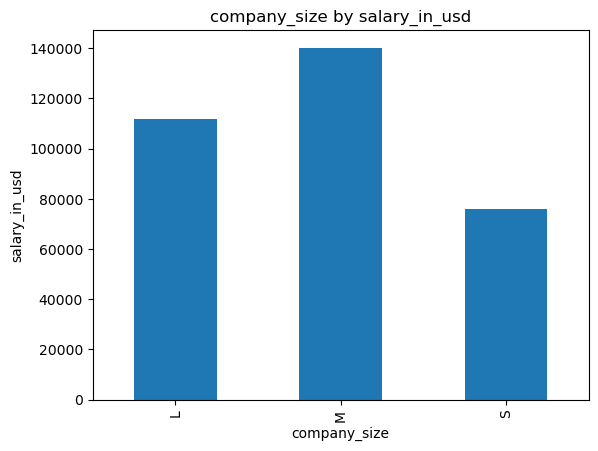

In [36]:
company_salary.plot(kind='bar')
plt.xlabel('company_size')
plt.ylabel('salary_in_usd')
plt.title('company_size by salary_in_usd')
plt.show()

In [57]:
#What country pays the highest
salary_country = df.groupby('company_location')['salary_in_usd'].mean().sort_values(ascending=False).head(10)
salary_country

company_location
PR    167500.000000
US    148260.358725
RU    140333.333333
CA    131917.689655
NZ    125000.000000
BA    120000.000000
IL    119059.000000
IE    114943.428571
JP    114127.333333
SE    105000.000000
Name: salary_in_usd, dtype: float64

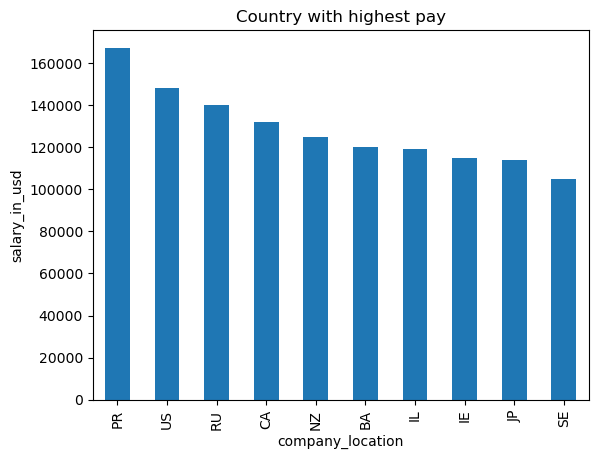

In [58]:
salary_country.plot(kind='bar')
plt.xlabel('company_location')
plt.ylabel('salary_in_usd')
plt.title('Country with highest pay')
plt.show()

In [54]:
#relationship btw remote work and salary,do they earn more or less
remote_salary = df.groupby('remote_ratio')['salary_in_usd'].mean()
remote_salary

remote_ratio
0      141082.325926
50      73761.989247
100    133251.019183
Name: salary_in_usd, dtype: float64

In [52]:
# emp type that pays the highest
emp_typ_salary = df.groupby('employment_type')['salary_in_usd'].mean().sort_values(ascending=False)
emp_typ_salary

employment_type
FT    135063.006838
CT     79829.888889
FL     51807.800000
PT     39533.705882
Name: salary_in_usd, dtype: float64

In [46]:
pd.crosstab(df["experience_level"],
            df["employment_type"])

employment_type,CT,FL,FT,PT
experience_level,,,,
EN,2,2,301,14
EX,0,0,100,0
MI,5,5,787,3
SE,2,3,2468,0


In [24]:
pd.crosstab(df["work_year"],
            df["employment_type"])

employment_type,CT,FL,FT,PT
work_year,,,,
2020,1,1,69,2
2021,2,3,216,7
2022,4,4,1629,7
2023,2,2,1742,1


In [29]:
df['employment_type'].unique()

array(['FT', 'CT', 'FL', 'PT'], dtype=object)

In [37]:
df['job_title'].value_counts().head(10)

job_title
Data Engineer                1024
Data Scientist                830
Data Analyst                  610
Machine Learning Engineer     283
Analytics Engineer            103
Data Architect                 99
Research Scientist             78
Applied Scientist              55
Data Science Manager           51
Research Engineer              37
Name: count, dtype: int64

In [35]:
#hw have salary changed over the years
yearly_salary = df.groupby('work_year')['salary_in_usd'].mean()
yearly_salary

work_year
2020     79835.616438
2021     91232.710526
2022    130935.461071
2023    145284.497424
Name: salary_in_usd, dtype: float64

In [61]:
correlation = df['remote_ratio'].corr(df['salary_in_usd'])
correlation

np.float64(-0.06982288060021404)

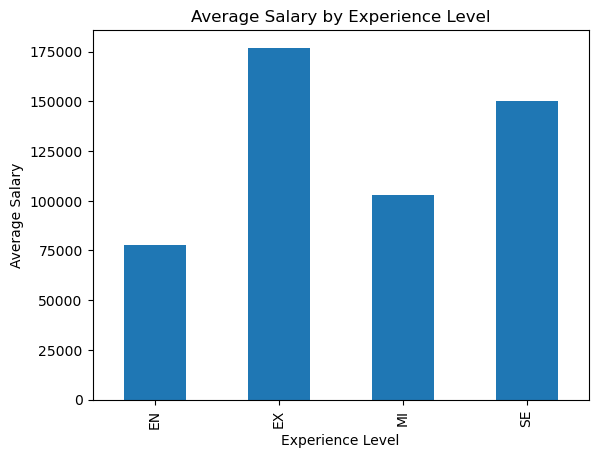

In [24]:
avg_salary_exp.plot(kind='bar')
plt.xlabel('Experience Level')
plt.ylabel('Average Salary')
plt.title('Average Salary by Experience Level')
plt.show()

In [25]:
#Who has the highest job salary

high_jobs = df.groupby('job_title')['salary_in_usd'].mean().sort_values(ascending=False)
(high_jobs).head(5)

#without .head() shows you the tops and down

job_title
Cloud Data Architect                   250000.0
Data Lead                              212500.0
Principal Data Engineer                192500.0
Principal Machine Learning Engineer    190000.0
Applied Scientist                      183028.0
Name: salary_in_usd, dtype: float64

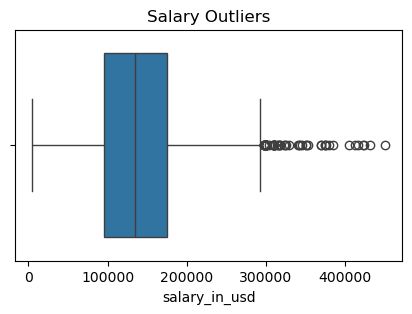

In [32]:
plt.figure(figsize=(5,3))
sns.boxplot(x=df["salary_in_usd"])
plt.title("Salary Outliers")
plt.show()

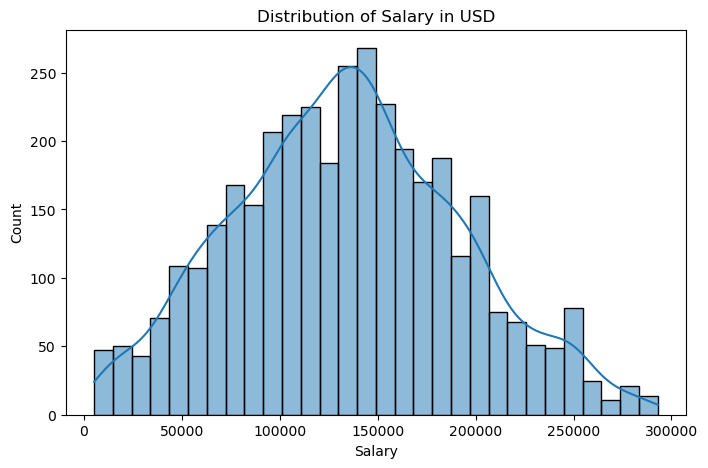

In [41]:
plt.figure(figsize=(8,5))

sns.histplot(df["salary_in_usd"],
             bins=30,
             kde=True)

plt.title("Distribution of Salary in USD")
plt.xlabel("Salary")
plt.show()

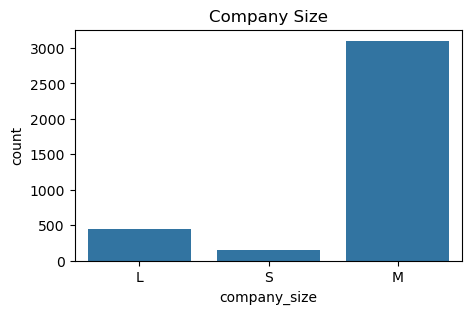

In [23]:
plt.figure(figsize=(5,3))

sns.countplot(data=df,x="company_size")

plt.title("Company Size")
plt.show()

<Axes: ylabel='job_title'>

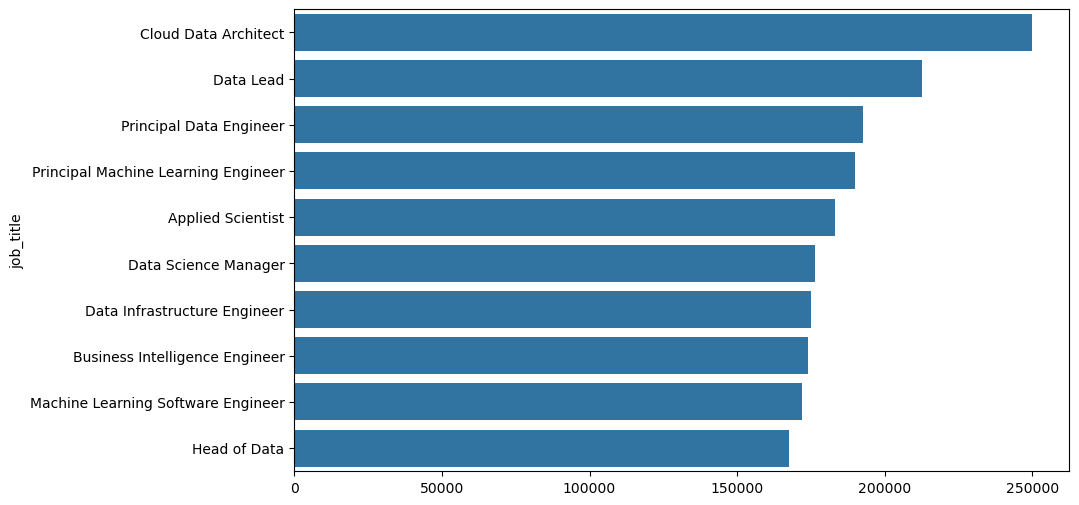

In [29]:
top_salary = (df.groupby("job_title")["salary_in_usd"].mean().sort_values(ascending=False).head(10))
plt.figure(figsize=(10,6))

sns.barplot(x=top_salary.values,y=top_salary.index)

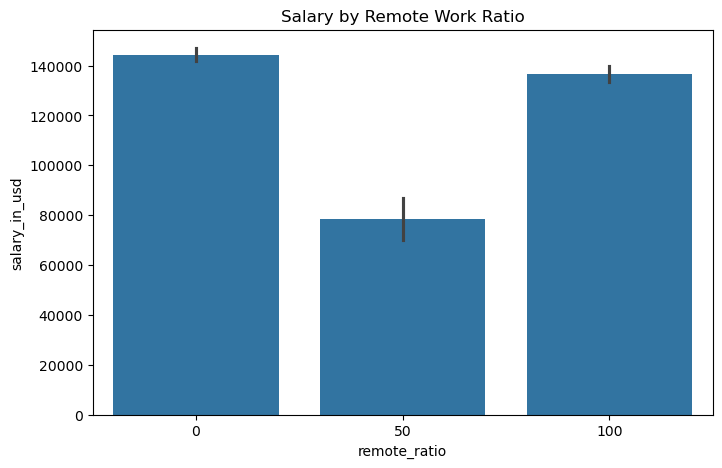

In [9]:
plt.figure(figsize=(8,5))
sns.barplot(data=df,x="remote_ratio", y="salary_in_usd")
plt.title("Salary by Remote Work Ratio")
plt.show()

Dataset shape (rows and columns).
Number of missing values.
Presence or absence of duplicate records.
Most common job title.
Most common employee residence.
Most common experience level.
Average salary.
Highest-paying job title.
Relationship between experience level and salary.
Relationship between company size and salary.
Distribution of remote work.
Presence of outliers in salaries.
Correlation among numerical variables.